# Approximation Test
Run all cells in order to train models, evaluate approximation error, and reproduce Figure 12(a)/(b) from the supplied preprocessed datasets.

Requirements: NumPy, scikit-learn, Matplotlib, and a Jupyter kernel. No pretrained models, repository modules, hardware tools, or output files are required. Edit DATASET_ROOT below if the datasets are elsewhere.

The existing train/test splits are retained. Feature selection uses training data only. As in model_prepare.py, LabelEncoder establishes class IDs from both label arrays; labels are not used to fit test features. KMeans cluster IDs are scored directly as class IDs, without cluster-to-label matching, to preserve the original experiment.

Configurations were inspected from the supplied models: seed 4567; KM uses 2/3 clusters and n_init=10; LR uses max_iter=1000; NB uses alpha=0.1 and 100 categories; SLP uses max_iter=1000 and tol=0.001. Feature counts are listed below. Retrained results can vary across package versions. Models and results remain in memory; both figures are displayed inline.

In [7]:
import warnings
from itertools import combinations
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import numpy as np
import sklearn
from sklearn.cluster import KMeans
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder

# Run from this notebook's directory, the artifact root, or the repository root.
candidates = [Path.cwd(), *Path.cwd().parents]
ARTIFACT_ROOT = next((root for base in candidates
                      for root in (base, base / "artifact_evaluation" / "github")
                      if (root / "datasets" / "cicids17").is_dir()), None)
DATASET_ROOT = ARTIFACT_ROOT / "datasets" if ARTIFACT_ROOT else Path("../datasets")
DATASETS = {"ds1": "cicids17", "ds2": "ciciot22"}
MODELS = ("km", "lr", "nb", "slp")
FEATURE_COUNTS = {"ds1": {"km": 11, "lr": 26, "nb": 7, "slp": 26},
                  "ds2": {"km": 3, "lr": 17, "nb": 25, "slp": 25}}
RANDOM_STATE = 4567
DOMAIN_MIN, DOMAIN_MAX = 0, 99
VERSIONS = ("original_float", "reformulated_float", "original_fixed", "reformulated_fixed")

NumPy 2.3.2; scikit-learn 1.7.1; Matplotlib 3.10.5
Datasets: C:\Users\zhudi.DESKTOP-AL823SE\OneDrive - University of Virginia\Projects\Shapeshifter\artifact_evaluation\github\datasets; feature domain: [0, 99]


In [8]:
# Load and validate the supplied splits; do not resplit or requantize.
datasets = {}
for dataset_id, dataset in DATASETS.items():
    directory = DATASET_ROOT / dataset
    X_train, X_test = (np.load(directory / f"X_{split}.npy") for split in ("train", "test"))
    y_train, y_test = (np.load(directory / f"Y_{split}.npy", allow_pickle=True).ravel()
                       for split in ("train", "test"))
    if X_train.ndim != 2 or X_test.ndim != 2 or X_train.shape[1] != X_test.shape[1]:
        raise ValueError(f"{dataset}: train/test feature dimensions differ")
    for split, X, y in (("train", X_train, y_train), ("test", X_test, y_test)):
        if len(X) == 0 or len(X) != len(y):
            raise ValueError(f"{dataset}/{split}: empty or mismatched features/labels")
        if not np.all(np.isfinite(X)) or np.any(X != np.rint(X)):
            raise ValueError(f"{dataset}/{split}: features must be finite quantized integers")
        if np.any(X < DOMAIN_MIN) or np.any(X > DOMAIN_MAX):
            raise ValueError(f"{dataset}/{split}: features must be within [0, 99]")
        values, counts = np.unique(y, return_counts=True)
    encoder = LabelEncoder().fit(np.concatenate([y_train, y_test]))
    if len(encoder.classes_) != (2 if dataset_id == "ds1" else 3):
        raise ValueError(f"{dataset}: expected {'two' if dataset_id == 'ds1' else 'three'} classes")
    datasets[dataset_id] = (X_train, X_test, encoder.transform(y_train),
                            encoder.transform(y_test), encoder)

cicids17/train: X=(285216, 45), dtype=int64, labels={0: 142764, 1: 142452}
cicids17/test: X=(71305, 45), dtype=int64, labels={0: 35692, 1: 35613}
ciciot22/train: X=(11878, 45), dtype=int64, labels={'Idle': 5939, 'Interactions': 2488, 'Power': 3451}
ciciot22/test: X=(2970, 45), dtype=int64, labels={'Idle': 1485, 'Interactions': 622, 'Power': 863}


In [9]:
# Match model_prepare.py: variance for KM, ANOVA F-score for LR/NB/SLP.
trained = {}
for dataset_id, (X_train, X_test, y_train, y_test, encoder) in datasets.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        supervised_scores, _ = f_classif(X_train, y_train)
    for model_type in MODELS:
        count = FEATURE_COUNTS[dataset_id][model_type]
        if not 1 <= count <= min(X_train.shape[1], 27):
            raise ValueError("Selected feature count exceeds the input or SS capacity")
        scores = np.var(X_train, axis=0) if model_type == "km" else supervised_scores
        scores = np.nan_to_num(np.asarray(scores, dtype=np.float64), nan=-np.inf,
                               posinf=np.finfo(np.float64).max, neginf=-np.inf)
        indices = np.sort(np.argsort(scores)[-count:])
        model = {
            "km": KMeans(n_clusters=len(encoder.classes_), n_init=10, random_state=RANDOM_STATE),
            "lr": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
            "nb": CategoricalNB(alpha=0.1, min_categories=100),
            "slp": Perceptron(max_iter=1000, tol=1e-3, random_state=RANDOM_STATE),
        }[model_type]
        name = f"{model_type}_{dataset_id}"
        train_features = X_train[:, indices]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            if model_type == "km":
                model.fit(train_features)
            else:
                model.fit(train_features, y_train)
        test_features = X_test[:, indices].astype(np.int64)
        trained[name] = {"model": model, "model_type": model_type, "dataset": DATASETS[dataset_id],
                         "indices": indices, "encoder": encoder, "features": test_features,
                         "labels": y_test}

Training km_ds1; selected indices: [0, 7, 9, 15, 17, 18, 20, 21, 34, 38, 39]


C:\Users\zhudi.DESKTOP-AL823SE\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [24 25 26 40] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
C:\Users\zhudi.DESKTOP-AL823SE\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


  Test accuracy: 0.8701
Training lr_ds1; selected indices: [0, 5, 7, 8, 9, 10, 13, 15, 17, 18, 19, 20, 21, 22, 23, 27, 28, 30, 31, 32, 34, 35, 36, 37, 38, 39]
  Test accuracy: 0.9819
Training nb_ds1; selected indices: [7, 9, 15, 17, 18, 38, 39]
  Test accuracy: 0.9395
Training slp_ds1; selected indices: [0, 5, 7, 8, 9, 10, 13, 15, 17, 18, 19, 20, 21, 22, 23, 27, 28, 30, 31, 32, 34, 35, 36, 37, 38, 39]
  Test accuracy: 0.9792
Training km_ds2; selected indices: [31, 34, 35]
  Test accuracy: 0.4609
Training lr_ds2; selected indices: [3, 4, 5, 7, 9, 15, 23, 24, 27, 28, 29, 30, 31, 34, 35, 43, 44]


C:\Users\zhudi.DESKTOP-AL823SE\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [13 16 19 25 26 32 36 37 38 39 40] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
C:\Users\zhudi.DESKTOP-AL823SE\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


  Test accuracy: 0.6478
Training nb_ds2; selected indices: [0, 2, 3, 4, 5, 7, 8, 9, 12, 14, 15, 17, 18, 23, 24, 27, 28, 29, 30, 31, 34, 35, 42, 43, 44]
  Test accuracy: 0.7562
Training slp_ds2; selected indices: [0, 2, 3, 4, 5, 7, 8, 9, 12, 14, 15, 17, 18, 23, 24, 27, 28, 29, 30, 31, 34, 35, 42, 43, 44]
  Test accuracy: 0.5276


In [10]:
# Numerical SS constraints only; no hardware artifacts are generated.
# Feature slots follow the converter's block-major order.
CELL_BUCKETS = tuple(block + lane for block in range(6) for lane in range(7)
                     if block + lane < 7)


def score_matrix(model, feature_count):
    coefficients = np.asarray(model.coef_, dtype=np.float64)
    intercepts = np.asarray(model.intercept_, dtype=np.float64).ravel()
    if len(model.classes_) == 2 and coefficients.shape[0] == 1:
        coefficients = np.vstack([np.zeros(feature_count), coefficients[0]])
        intercepts = np.array([0.0, intercepts[0]])
    return tuple(model.classes_), coefficients, intercepts


logistic_regression_score_matrix = score_matrix
perceptron_score_matrix = score_matrix


def reformulated_contributions(model, model_type):
    classes = tuple(range(model.n_clusters if model_type == "km" else len(model.classes_)))
    pairs = tuple(combinations(classes, 2))
    domain = np.arange(DOMAIN_MIN, DOMAIN_MAX + 1, dtype=np.float64)
    if model_type == "nb":
        result = np.stack([np.stack([values[left] - values[right]
                                    for values in model.feature_log_prob_])
                           for left, right in pairs])
        for i, (left, right) in enumerate(pairs):
            result[i, 0] += model.class_log_prior_[left] - model.class_log_prior_[right]
    else:
        if model_type == "km":
            coefficients = 2.0 * model.cluster_centers_
            intercepts = -np.sum(model.cluster_centers_ * model.cluster_centers_, axis=1)
        else:
            _, coefficients, intercepts = score_matrix(model, model.n_features_in_)
        result = np.stack([(coefficients[left] - coefficients[right])[:, None] * domain[None, :]
                           for left, right in pairs])
        for i, (left, right) in enumerate(pairs):
            result[i, 0] += float(intercepts[left] - intercepts[right])
    return classes, pairs, result


def pairwise_predictions(scores, classes, pairs):
    votes = np.zeros((len(scores), len(classes)), dtype=np.int64)
    for i, (left, right) in enumerate(pairs):
        votes[:, left] += scores[:, i] >= 0
        votes[:, right] += scores[:, i] < 0
    return votes.argmax(axis=1)



def original_contributions(model, model_type):
    domain = np.arange(DOMAIN_MIN, DOMAIN_MAX + 1, dtype=np.float64)
    if model_type == "km":
        return -(domain[None, None, :] - model.cluster_centers_[:, :, None]) ** 2
    if model_type == "nb":
        contributions = np.stack(
            [values[:, domain.astype(np.int64)] for values in model.feature_log_prob_], axis=1
        )
        contributions[:, 0, :] += model.class_log_prior_[:, None]
        return contributions
    score_matrix = logistic_regression_score_matrix if model_type == "lr" else perceptron_score_matrix
    _, coefficients, intercepts = score_matrix(model, model.n_features_in_)
    contributions = coefficients[:, :, None] * domain[None, None, :]
    contributions[:, 0, :] += intercepts[:, None]
    return contributions


def accumulate(contributions, features):
    scores = np.zeros((len(features), contributions.shape[0]), dtype=contributions.dtype)
    for feature_slot in range(features.shape[1]):
        scores += contributions[:, feature_slot, features[:, feature_slot] - DOMAIN_MIN].T
    return scores


def scale_fits(contributions, scale):
    rounded = np.rint(contributions * scale)
    low, high = rounded.min(axis=2), rounded.max(axis=2)
    if np.any(low < -32768) or np.any(high > 32767):
        return False
    # Keep the original feature-slot order within each of the seven buckets.
    buckets = np.asarray(CELL_BUCKETS[:contributions.shape[1]])
    ranges = np.array([(low[:, buckets == bucket].sum(axis=1),
                        high[:, buckets == bucket].sum(axis=1))
                       for bucket in range(7)])
    prefixes = ranges.cumsum(axis=0)
    return bool(np.all(ranges[:, 0] >= -32768) and np.all(ranges[:, 1] <= 32767)
                and np.all(prefixes[:, 0] >= -32768) and np.all(prefixes[:, 1] <= 32767))


def quantize(contributions):
    contributions = np.asarray(contributions, dtype=np.float64)
    if contributions.ndim != 3 or not 1 <= contributions.shape[0] <= 3:
        raise ValueError("Expected one to three contribution channels")
    if not 1 <= contributions.shape[1] <= len(CELL_BUCKETS) or not np.all(np.isfinite(contributions)):
        raise ValueError("Contributions must be finite and fit the feature capacity")
    factor = 1.0
    normalized = contributions
    while not scale_fits(normalized, 1):
        factor *= 2.0
        if not np.isfinite(factor):
            raise ValueError("Score normalization factor overflowed")
        normalized = contributions / factor
    low, high, best = 1, 32767, 1
    while low <= high:
        scale = (low + high) // 2
        if scale_fits(normalized, scale):
            best, low = scale, scale + 1
        else:
            high = scale - 1
    return np.rint(normalized * best).astype(np.int64), best, factor


def floating_point_diagnostics(model_type, original, reformulated, contributions, features, pairs):
    scores = accumulate(contributions, features)
    for pair_index, (left, right) in enumerate(pairs):
        expected = scores[:, left] - scores[:, right]
        actual = accumulate(reformulated[pair_index:pair_index + 1], features)[:, 0]
        tolerance = 64 * np.finfo(np.float64).eps * features.shape[1] * (
            1 + np.abs(scores[:, left]) + np.abs(scores[:, right])
        )
        if np.any(np.abs(expected - actual) > tolerance):
            raise ValueError("pairwise contributions differ from direct class-score differences")
    classes = tuple(range(scores.shape[1]))
    prediction = pairwise_predictions(accumulate(reformulated, features), classes, pairs)
    differing = prediction != original
    if not np.any(differing):
        return ""
    margins = np.sort(scores[differing], axis=1)
    gaps = margins[:, -1] - margins[:, -2]
    tolerance = 64 * np.finfo(np.float64).eps * features.shape[1] * (
        1 + np.max(np.abs(scores[differing]), axis=1)
    )
    if np.any(gaps > tolerance):
        raise ValueError(f"{model_type}: floating-point predictions differ away from score ties")
    return f"{int(differing.sum())} raw predictions differ at ties or within floating-point tolerance"

In [11]:
def evaluate_model(name, artifacts):
    model, model_type = artifacts["model"], artifacts["model_type"]
    features, labels = artifacts["features"], artifacts["labels"]
    dataset = artifacts["dataset"]
    classes, pairs, reformulated = reformulated_contributions(model, model_type)
    mapping = np.arange(len(classes))
    original = model.predict(features).copy()
    contributions = original_contributions(model, model_type)
    notes = floating_point_diagnostics(
        model_type, original, reformulated, contributions, features, pairs
    )
    variants = [("original_float", original, None, None, ""),
                ("reformulated_float", pairwise_predictions(
                    accumulate(reformulated, features), classes, pairs), None, None, notes)]
    rounded, scale, factor = quantize(contributions)
    variants.append(("original_fixed", accumulate(rounded, features).argmax(axis=1), scale, factor, ""))
    rounded, scale, factor = quantize(reformulated)
    variants.append(("reformulated_fixed", pairwise_predictions(
        accumulate(rounded, features), classes, pairs), scale, factor, ""))
    baseline = mapping[original]
    baseline_accuracy = accuracy_score(labels, baseline)
    baseline_f1 = f1_score(labels, baseline, labels=list(classes), average="macro", zero_division=0)
    rows = []
    for variant, raw_predictions, scale, factor, notes in variants:
        predictions = mapping[raw_predictions]
        accuracy = accuracy_score(labels, predictions)
        macro_f1 = f1_score(labels, predictions, labels=list(classes), average="macro", zero_division=0)
        if np.unique(np.concatenate((baseline, predictions))).size == 1:
            kappa = float("nan")
            notes = (notes + "; kappa undefined: both predictions contain the same single label").lstrip("; ")
        else:
            kappa = cohen_kappa_score(baseline, predictions)
        rows.append({
            "model": name, "dataset": dataset, "variant": variant, "sample_count": len(labels),
            "accuracy": accuracy, "macro_f1": macro_f1, "kappa_vs_original": kappa,
            "accuracy_change_pp": 100 * (accuracy - baseline_accuracy),
            "macro_f1_change_pp": 100 * (macro_f1 - baseline_f1),
            "fixed_point_scale": scale, "normalization_factor": factor,
            "effective_scale": None if scale is None else scale / factor,
            "domain_min": DOMAIN_MIN, "domain_max": DOMAIN_MAX,
            "sklearn_version": sklearn.__version__,
            "cluster_label_mapping": mapping.tolist() if model_type == "km" else "",
            "notes": notes,
        })
    return rows


results = []
for name, artifacts in trained.items():
    model_rows = evaluate_model(name, artifacts)
    results.extend(model_rows)
assert len(trained) == 8 and len(results) == 32

Model        Variant                 Accuracy   Macro-F1      Kappa
km_ds1       original_float            0.8701     0.8696   1.000000
km_ds1       reformulated_float        0.8701     0.8696   1.000000
km_ds1       original_fixed            0.8701     0.8696   0.999972
km_ds1       reformulated_fixed        0.8700     0.8695   0.999829
lr_ds1       original_float            0.9819     0.9819   1.000000
lr_ds1       reformulated_float        0.9819     0.9819   1.000000
lr_ds1       original_fixed            0.9817     0.9817   0.999299
lr_ds1       reformulated_fixed        0.9817     0.9817   0.999299
nb_ds1       original_float            0.9395     0.9394   1.000000
nb_ds1       reformulated_float        0.9395     0.9394   1.000000
nb_ds1       original_fixed            0.9395     0.9394   1.000000
nb_ds1       reformulated_fixed        0.9395     0.9394   1.000000
slp_ds1      original_float            0.9792     0.9792   1.000000
slp_ds1      reformulated_float        0.9792   

# Plot Figure 12(a) and Figure 12(b)
V1: original float; V2: reformulated float; V3: original fixed; V4: reformulated fixed. Bars show macro-F1; black lines show Cohen’s kappa against V1.

The numerical helpers above preserve the evaluator’s per-feature contributions, pairwise votes (ties favor the lower class ID), 16-bit accumulator bounds, normalization, and fixed-point scale search. Floating-point discrepancies are accepted only at score ties or within numerical tolerance.

In [12]:
SHOW_LEGEND = False
LEGEND_LOC, LEGEND_BBOX_TO_ANCHOR = "lower center", (0.5, 0.0)
FIGURE_SIZE = (10, 4)
LABELS = ("V1", "V2", "V3", "V4")
HATCHES = ("///", "\\\\", "xxx", "...")
COLORS = tuple(tuple(0.6 * channel + 0.4 for channel in to_rgb(color))
               for color in ("tab:blue", "tab:orange", "tab:green", "tab:red"))


def plot_approx_error(dataset):
    if dataset not in DATASETS.values():
        raise ValueError(f"Unknown dataset: {dataset}")
    rows = [row for row in results if row["dataset"] == dataset]
    values = {(row["model"].split("_")[0], row["variant"]): row for row in rows}
    expected = {(model, version) for model in MODELS for version in VERSIONS}
    if len(rows) != 16 or set(values) != expected:
        raise ValueError(f"Expected all 16 unique model/version results for {dataset}")
    plt.rcParams.update({"font.family": "Times New Roman", "font.size": 14, "pdf.fonttype": 42})
    figure, f1_axis = plt.subplots(figsize=FIGURE_SIZE)
    kappa_axis = f1_axis.twinx()
    width = 0.18
    for model_index, model in enumerate(MODELS):
        positions = model_index + (np.arange(4) - 1.5) * width
        f1 = [values[(model, version)]["macro_f1"] for version in VERSIONS]
        kappa = [values[(model, version)]["kappa_vs_original"] for version in VERSIONS]
        metrics = np.asarray([f1, kappa])
        if not np.all(np.isfinite(metrics)) or np.any((metrics < 0) | (metrics > 1)):
            raise ValueError(f"Invalid metrics for {dataset}/{model}")
        for index, position in enumerate(positions):
            f1_axis.bar(position, f1[index], width=width, facecolor=COLORS[index],
                        edgecolor="black", linewidth=0.8, hatch=HATCHES[index])
        kappa_axis.plot(positions, kappa, color="black", marker="o", markersize=5,
                        linewidth=1.5, clip_on=False)
        for index, (position, value) in enumerate(zip(positions, kappa)):
            text = "1.0" if value == 1 else f"{min(np.trunc(value * 1000) / 1000, 0.99):.2f}"
            above = index % 2 == 0
            kappa_axis.annotate(text, (position, value), xytext=(0, 5 if above else -5),
                                textcoords="offset points", ha="center", va="bottom" if above else "top",
                                color="black", fontsize=20, annotation_clip=False, clip_on=False)
    for axis, label in ((f1_axis, "Macro-F1"), (kappa_axis, "Cohen’s kappa")):
        axis.set_xticks(np.arange(len(MODELS)), [model.upper() for model in MODELS])
        axis.set_ylabel(label, fontsize=24)
        axis.tick_params(axis="both", which="both", labelsize=24)
        axis.set_axisbelow(True)
        axis.spines["top"].set_visible(False)
    f1_axis.set_ylim(0, max(bar.get_height() for bar in f1_axis.patches) + 0.20)
    kappa_axis.set_ylim(0, 1)
    f1_axis.grid(axis="y", alpha=0.25)
    if SHOW_LEGEND:
        handles = [Patch(facecolor=color, edgecolor="black", hatch=hatch, label=label)
                   for color, hatch, label in zip(COLORS, HATCHES, LABELS)]
        handles += [Patch(facecolor="none", edgecolor="black", label="Macro-F1 (bars)"),
                    Line2D([], [], color="black", marker="o", label="Cohen’s kappa (lines)")]
        legend = kappa_axis.legend(handles=handles, loc=LEGEND_LOC, ncol=3,
                                   bbox_to_anchor=LEGEND_BBOX_TO_ANCHOR, frameon=True,
                                   facecolor="white", framealpha=1, fontsize=16)
        legend.get_frame().set_linewidth(0.8)
    figure.tight_layout()
    plt.show()
    plt.close(figure)

## Plot Figure 12(a)

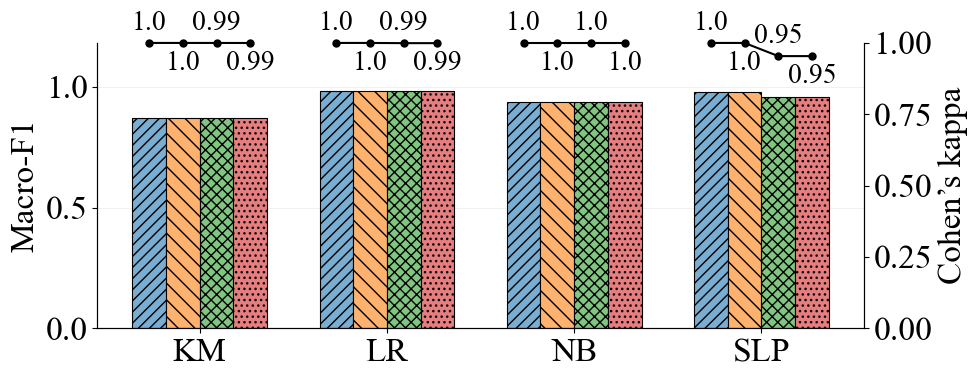

In [13]:
plot_approx_error("cicids17")

## Plot Figure 12(b)

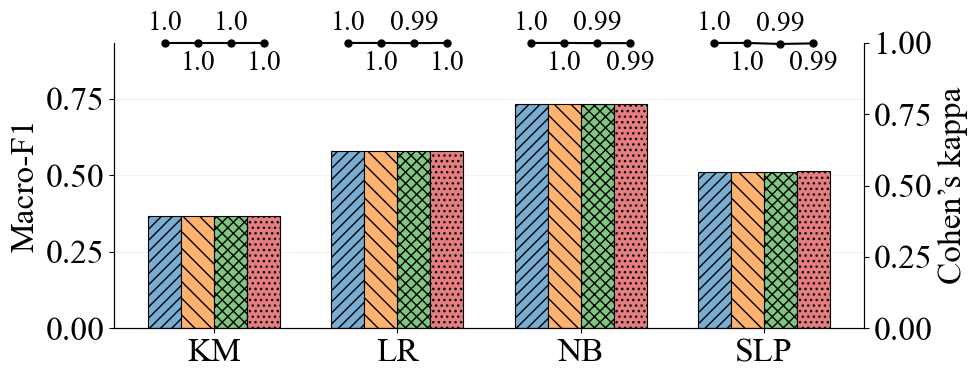

In [14]:
plot_approx_error("ciciot22")